In [12]:
# 1. Load dataset (Kaggle: vijayaadithyanvg/car-price-predictionused-cars)
try:
    import kagglehub
    folder = kagglehub.dataset_download("vijayaadithyanvg/car-price-predictionused-cars")
    CSV_PATH = glob.glob(os.path.join(folder, "*.csv"))[0]
except Exception as e:
    print("kagglehub failed, using local 'car data.csv':", e)
    CSV_PATH = "car data.csv"
print("Using file:", CSV_PATH)
df = pd.read_csv(CSV_PATH)
df.columns = [c.strip() for c in df.columns]
print("Shape:", df.shape)
print(df.head(), "\n")
df.info()

Using Colab cache for faster access to the 'car-price-predictionused-cars' dataset.
Using file: /kaggle/input/car-price-predictionused-cars/car data.csv
Shape: (301, 9)
  Car_Name  Year  Selling_Price  Present_Price  Driven_kms Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Selling_type Transmission  Owner  
0       Dealer       Manual      0  
1       Dealer       Manual      0  
2       Dealer       Manual      0  
3       Dealer       Manual      0  
4       Dealer       Manual      0   

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         ------

In [13]:
import os, glob
os.makedirs("/content/car", exist_ok=True); os.chdir("/content/car")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [14]:
# 1. Load dataset (Kaggle: vijayaadithyanvg/car-price-predictionused-cars)
try:
    import kagglehub
    folder = kagglehub.dataset_download("vijayaadithyanvg/car-price-predictionused-cars")
    CSV_PATH = glob.glob(os.path.join(folder, "*.csv"))[0]
except Exception as e:
    print("kagglehub failed, using local 'car data.csv':", e)
    CSV_PATH = "car data.csv"
print("Using file:", CSV_PATH)
df = pd.read_csv(CSV_PATH)
df.columns = [c.strip() for c in df.columns]
print("Shape:", df.shape)
print(df.head(), "\n")
df.info()

Using Colab cache for faster access to the 'car-price-predictionused-cars' dataset.
Using file: /kaggle/input/car-price-predictionused-cars/car data.csv
Shape: (301, 9)
  Car_Name  Year  Selling_Price  Present_Price  Driven_kms Fuel_Type  \
0     ritz  2014           3.35           5.59       27000    Petrol   
1      sx4  2013           4.75           9.54       43000    Diesel   
2     ciaz  2017           7.25           9.85        6900    Petrol   
3  wagon r  2011           2.85           4.15        5200    Petrol   
4    swift  2014           4.60           6.87       42450    Diesel   

  Selling_type Transmission  Owner  
0       Dealer       Manual      0  
1       Dealer       Manual      0  
2       Dealer       Manual      0  
3       Dealer       Manual      0  
4       Dealer       Manual      0   

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         ------

In [15]:
# 2. Target column
price_cols = [c for c in df.columns if "price" in c.lower()]
target = next((c for c in price_cols if "selling" in c.lower()), None) or \
         next((c for c in price_cols if c.lower() == "price"), None) or price_cols[0]
print("\nTarget column:", target)



Target column: Selling_Price


In [16]:
# 3. Cleaning
print("Duplicates:", df.duplicated().sum(), "| Missing:", df.isnull().sum().sum())
df = df.drop_duplicates()
df = df.drop(columns=[c for c in df.columns if c.lower() in ("car_id", "id", "unnamed: 0")], errors="ignore")
df = df.dropna(subset=[target])

Duplicates: 2 | Missing: 0


In [17]:
 # 4. Feature engineering
for col in list(df.columns):
    if col.lower() == "year":
        df["Car_Age"] = pd.Timestamp.today().year - df[col]
        df = df.drop(columns=col)
    elif col.lower() in ("carname", "car_name", "name"):
        df["Car_Model"] = df[col].astype(str).str.split().str[0].str.lower()
        df = df.drop(columns=col)

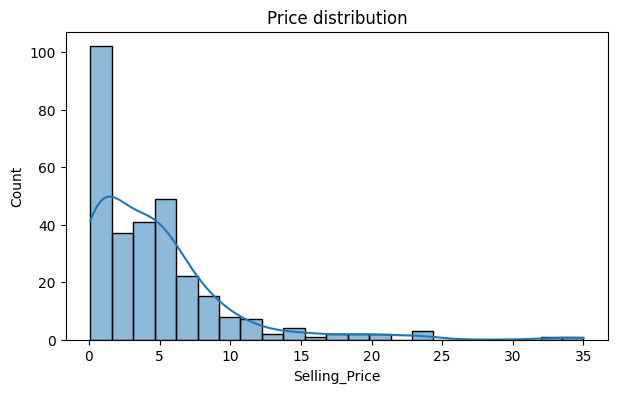

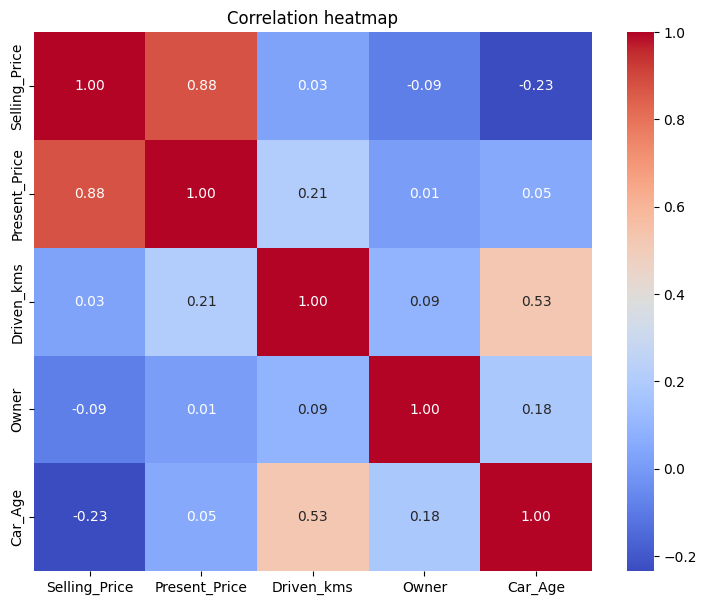

In [18]:
# 5. EDA
plt.figure(figsize=(7, 4))
sns.histplot(df[target], kde=True)
plt.title("Price distribution")
plt.savefig("price_distribution.png", dpi=120, bbox_inches="tight"); plt.show()
num_all = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_all].corr(), annot=len(num_all) <= 12, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.savefig("correlation_heatmap.png", dpi=120, bbox_inches="tight"); plt.show()

In [19]:
# 6. Split + preprocessing
X = df.drop(columns=target)
y = df[target]
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}


In [20]:
# 7. Train & evaluate
rows, fitted = [], {}
for name, m in models.items():
    pipe = Pipeline([("pre", pre), ("model", m)])
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2").mean()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append([name, cv_r2, r2_score(y_test, pred), mean_absolute_error(y_test, pred),
                 np.sqrt(mean_squared_error(y_test, pred))])
    fitted[name] = pipe
res = pd.DataFrame(rows, columns=["Model", "CV R2", "Test R2", "MAE", "RMSE"]).sort_values("Test R2", ascending=False)
print(res.to_string(index=False), "\n")
best_name = res.iloc[0]["Model"]
best = fitted[best_name]
pred = best.predict(X_test)
print("Best model:", best_name)

            Model    CV R2  Test R2      MAE     RMSE
            Ridge 0.854971 0.775802 1.345831 2.403812
Gradient Boosting 0.887557 0.735596 1.149082 2.610471
Linear Regression 0.752825 0.697124 1.473767 2.793941
    Random Forest 0.888046 0.579471 1.371377 3.292173 

Best model: Ridge


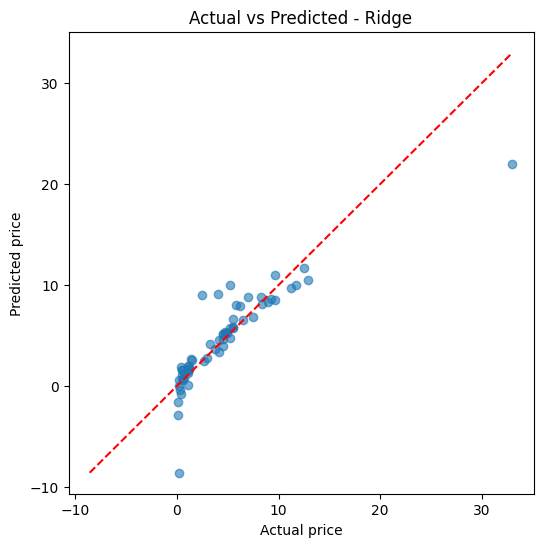

In [21]:
# 8. Actual vs Predicted
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.6)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title(f"Actual vs Predicted - {best_name}")
plt.savefig("actual_vs_predicted.png", dpi=120, bbox_inches="tight"); plt.show()

In [22]:
# 9. Feature importance (tree models)
final = best.named_steps["model"]
if hasattr(final, "feature_importances_"):
    names = best.named_steps["pre"].get_feature_names_out()
    imp = pd.Series(final.feature_importances_, index=names).sort_values(ascending=False).head(15)
    imp.iloc[::-1].plot(kind="barh", figsize=(8, 6), title="Top 15 feature importances")
    plt.savefig("feature_importance.png", dpi=120, bbox_inches="tight"); plt.show()
    print(imp.head(10))